In [9]:
features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "yr_built",
    "yr_renovated"
]
print("Our Target will now be price_category")


Our Target will now be price_category


Import libraries and load dataset

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    average_precision_score
)

from sklearn.utils.class_weight import compute_class_weight

print("Libraries imported successfully!")


Mounted at /content/drive
Libraries imported successfully!


In [4]:

file_path = "/content/drive/MyDrive/Hamza - AI ML-Learning/Day_1/data.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (4600, 18)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


Create target variable

In [5]:

# Calculate median house price
median_price = df["price"].median()

# Create binary classification target
df["price_category"] = (
    df["price"] > median_price
).astype(int)

print("Median House Price:", median_price)

print("\nClass Distribution:")
print(df["price_category"].value_counts())

print("\nClass Percentages:")
print(
    df["price_category"]
    .value_counts(normalize=True) * 100
)


Median House Price: 460943.46153850004

Class Distribution:
price_category
0    2300
1    2300
Name: count, dtype: int64

Class Percentages:
price_category
0    50.0
1    50.0
Name: proportion, dtype: float64


Define X and Y

In [6]:

features = [
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "yr_built",
    "yr_renovated"
]

X = df[features]
y = df["price_category"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (4600, 10)
Target Shape: (4600,)


Train-test split

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))


Training Shape: (3680, 10)
Testing Shape: (920, 10)

Training Class Distribution:
price_category
1    0.5
0    0.5
Name: proportion, dtype: float64

Testing Class Distribution:
price_category
0    0.5
1    0.5
Name: proportion, dtype: float64


Train baseline Logistic Regression

In [8]:

baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained!")


Baseline Logistic Regression trained!


Generate predictions and probabilities

In [10]:

# Predicted classes using default threshold 0.5
y_pred = baseline_model.predict(X_test)

# Predicted probabilities for expensive houses
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("First 10 Actual Labels:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

print("\nFirst 10 Predicted Probabilities:")
print(y_prob[:10].round(3))


First 10 Actual Labels:
[0 1 0 1 1 0 1 1 0 1]

First 10 Predicted Labels:
[0 1 0 0 0 1 1 1 0 1]

First 10 Predicted Probabilities:
[0.383 0.733 0.433 0.247 0.248 0.677 0.526 0.83  0.406 0.992]


Confusion Matrix

Confusion Matrix:
[[350 110]
 [124 336]]


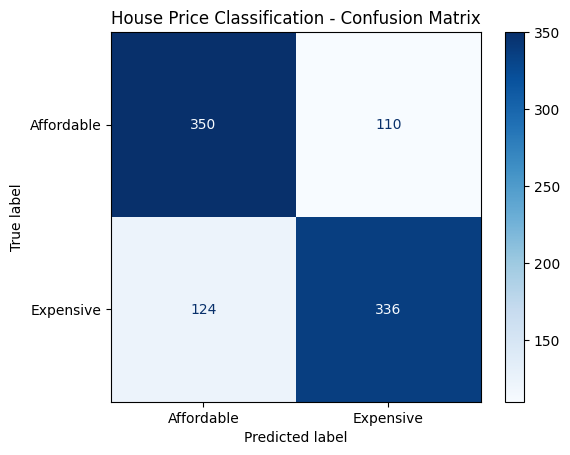

In [11]:

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Affordable", "Expensive"]
)

display_matrix.plot(cmap="Blues")
plt.title("House Price Classification - Confusion Matrix")
plt.show()


Calculate Precision, Recall and F1

In [12]:

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Affordable", "Expensive"]
    )
)


Accuracy: 0.7456521739130435
Precision: 0.7533632286995515
Recall: 0.7304347826086957
F1 Score: 0.7417218543046358

Classification Report:
              precision    recall  f1-score   support

  Affordable       0.74      0.76      0.75       460
   Expensive       0.75      0.73      0.74       460

    accuracy                           0.75       920
   macro avg       0.75      0.75      0.75       920
weighted avg       0.75      0.75      0.75       920



Precision-Recall Curve

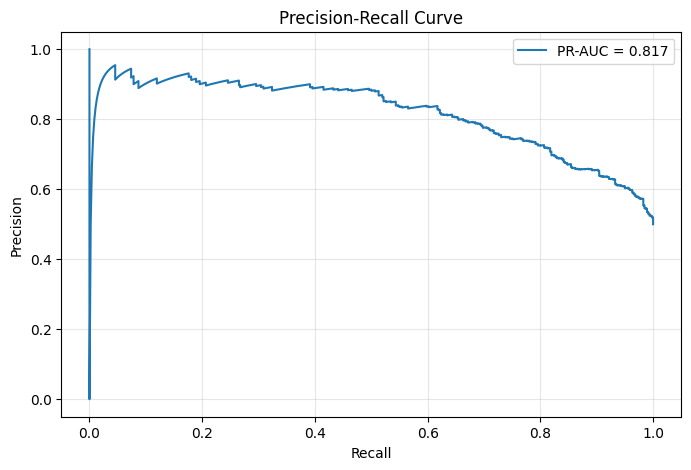

PR-AUC: 0.8174


In [13]:

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"PR-AUC = {pr_auc:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("PR-AUC:", round(pr_auc, 4))


Threshold Tuning

In [14]:

thresholds_to_test = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

threshold_results = []

for threshold in thresholds_to_test:

    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.2,0.6609,0.6008,0.9587,0.7387
1,0.3,0.7130,0.6581,0.8870,0.7556
2,0.4,0.7467,0.7162,0.8174,0.7635
3,0.5,0.7457,0.7534,0.7304,0.7417
4,0.6,0.7424,0.8123,0.6304,0.7099
5,0.7,0.7196,0.8686,0.5174,0.6485
6,0.8,0.6663,0.8964,0.3761,0.5299


Visualize the results:

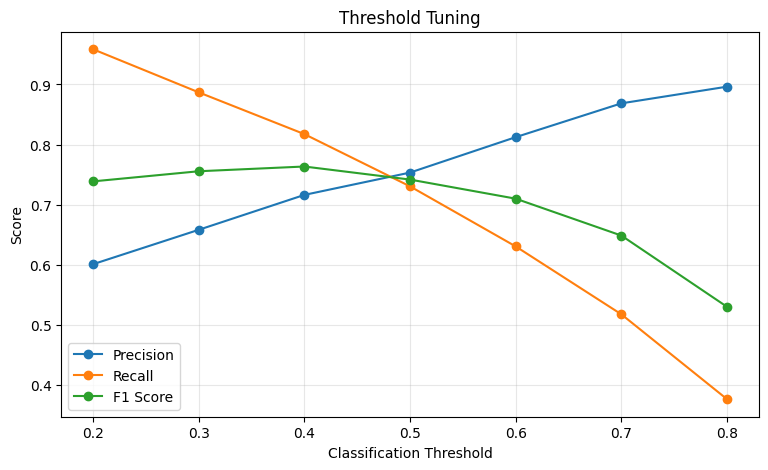

In [15]:

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Tuning")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


Handle Class Imbalance with Class Weights

In [16]:

weighted_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

weighted_model.fit(X_train, y_train)

print("Class-weighted model trained!")


Class-weighted model trained!


Evaluate the weighted model

In [17]:

weighted_pred = weighted_model.predict(X_test)

weighted_prob = weighted_model.predict_proba(X_test)[:, 1]

print("Weighted Model Results")

print("Accuracy:", accuracy_score(y_test, weighted_pred))

print("Precision:", precision_score(y_test, weighted_pred))

print("Recall:", recall_score(y_test, weighted_pred))

print("F1 Score:", f1_score(y_test, weighted_pred))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, weighted_pred))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        weighted_pred,
        target_names=["Affordable", "Expensive"]
    )
)


Weighted Model Results
Accuracy: 0.7456521739130435
Precision: 0.7533632286995515
Recall: 0.7304347826086957
F1 Score: 0.7417218543046358

Confusion Matrix:
[[350 110]
 [124 336]]

Classification Report:
              precision    recall  f1-score   support

  Affordable       0.74      0.76      0.75       460
   Expensive       0.75      0.73      0.74       460

    accuracy                           0.75       920
   macro avg       0.75      0.75      0.75       920
weighted avg       0.75      0.75      0.75       920



Compare baseline vs class-weighted model

In [18]:

comparison = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_prob)
    },
    {
        "Model": "Class Weighted Logistic Regression",
        "Accuracy": accuracy_score(y_test, weighted_pred),
        "Precision": precision_score(y_test, weighted_pred),
        "Recall": recall_score(y_test, weighted_pred),
        "F1 Score": f1_score(y_test, weighted_pred),
        "PR-AUC": average_precision_score(y_test, weighted_prob)
    }
])

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Baseline Logistic Regression,0.7457,0.7534,0.7304,0.7417,0.8174
1,Class Weighted Logistic Regression,0.7457,0.7534,0.7304,0.7417,0.8174
